# Brasil x EUA em Números

Comparação entre Brasil e Estados Unidos a partir de dados públicos oficiais,
em nível estadual: **população, densidade demográfica, renda e escolaridade
superior**.

**Fontes:**
- Brasil: [API SIDRA/IBGE](https://sidra.ibge.gov.br/) — Estimativas de População, Censo Demográfico (área) e PNAD Contínua (renda e escolaridade), 27 UFs
- EUA: [US Census Bureau — ACS 5-Year 2022](https://www.census.gov/data/developers/data-sets/acs-5year.html) (população, renda, escolaridade) + [Census Gazetteer Files](https://www.census.gov/geographies/reference-files/time-series/geo/gazetteer-files.html) (área, agregada a partir dos condados), 50 estados + Distrito de Columbia

O dataset comparativo já vem pronto de `src/fetch_ibge.py` + `src/fetch_census.py`
+ `src/clean_merge.py` — ver o `README.md` do projeto para rodar a coleta do zero.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("../data/processed/brasil_eua_estados.csv")
df.head()


,pais,unidade_sigla,unidade_nome,regiao,populacao,area_km2,densidade_hab_km2,renda_valor,renda_moeda,renda_unidade,renda_indice_relativo,pct_educacao_superior
0,Brasil,AC,Acre,Norte,887794,164122.3,5.409344,2438,BRL,"individual, mensal",78.404421,19.2
1,Brasil,AL,Alagoas,Nordeste,3221128,27779.3,115.954254,2281,BRL,"individual, mensal",73.355408,14.3
2,Brasil,AP,Amapá,Norte,809953,142827.9,5.670832,2857,BRL,"individual, mensal",91.879176,23.6
3,Brasil,AM,Amazonas,Norte,4360926,1559161.7,2.796968,2527,BRL,"individual, mensal",81.266601,18.4
4,Brasil,BA,Bahia,Nordeste,14889472,564830.9,26.360937,2162,BRL,"individual, mensal",69.528449,13.1


## 1. Visão geral dos dados

Uma ressalva importante antes de qualquer gráfico: **os dois países não
medem tudo do mesmo jeito**. A tabela abaixo resume as diferenças de
metodologia entre IBGE e Census que valem a pena ter em mente.

| Indicador | Brasil (IBGE) | EUA (Census) |
|---|---|---|
| Renda | Individual, mensal, `R$` (PNAD Contínua) | Domiciliar, anual, mediana, `US$` (ACS) |
| Escolaridade | % de 25+ anos com superior **completo** | % de 25+ anos com bacharelado **ou mais** |
| Densidade | Área do Censo 2010 | Área somada dos condados (Gazetteer 2021) |

Por isso a renda é analisada como **índice relativo à média do próprio país**
(`renda_indice_relativo`), não em valor bruto — comparar `R$` com `US$`
diretamente não diria nada útil.


In [2]:
df.shape[0], df.pais.value_counts()


(78,
 pais
 Estados Unidos    51
 Brasil            27
 Name: count, dtype: int64)

In [3]:
df.groupby("pais")[["populacao", "densidade_hab_km2", "renda_indice_relativo", "pct_educacao_superior"]].describe().T


pais                               Brasil  Estados Unidos
populacao             count  2.700000e+01    5.100000e+01
                      mean   7.933776e+06    6.492110e+06
                      std    9.291461e+06    7.392321e+06
                      min    7.610120e+05    5.779290e+05
                      25%    2.978156e+06    1.823538e+06
                      50%    4.182828e+06    4.502935e+06
                      75%    9.442694e+06    7.430416e+06
                      max    4.617901e+07    3.935610e+07
densidade_hab_km2     count  2.700000e+01    5.100000e+01
                      mean   7.662608e+01    1.398186e+02
                      std    1.198637e+02    5.274391e+02
                      min    2.796968e+00    4.261505e-01
                      25%    7.206527e+00    1.900173e+01
                      50%    3.658920e+01    3.703458e+01
                      75%    8.844947e+01    8.145089e+01
                      max    5.200587e+02    3.788075e+03
renda_indice_relativo count  2.700000e+01    5.100000e+01
                      mean   1.000000e+02    1.000000e+02
                      std    2.999511e+01    1.661892e+01
                      min    6.570149e+01    7.083079e+01
                      25%    7.721453e+01    8.911900e+01
                      50%    9.596341e+01    9.686246e+01
                      75%    1.142138e+02    1.140852e+02
                      max    2.087783e+02    1.359828e+02
pct_educacao_superior count  2.700000e+01    5.100000e+01
                      mean   2.016667e+01    3.387565e+01
                      std    5.998397e+00    6.718092e+00
                      min    1.290000e+01    2.271116e+01
                      25%    1.550000e+01    3.024454e+01
                      50%    1.970000e+01    3.346334e+01
                      75%    2.300000e+01    3.647600e+01
                      max    4.130000e+01    6.263609e+01

## 2. População: os 15 estados mais populosos

Brasil e EUA têm população total parecida (~213M x ~333M), mas a
distribuição entre estados é bem diferente. São Paulo sozinho tem mais
gente que qualquer estado americano.


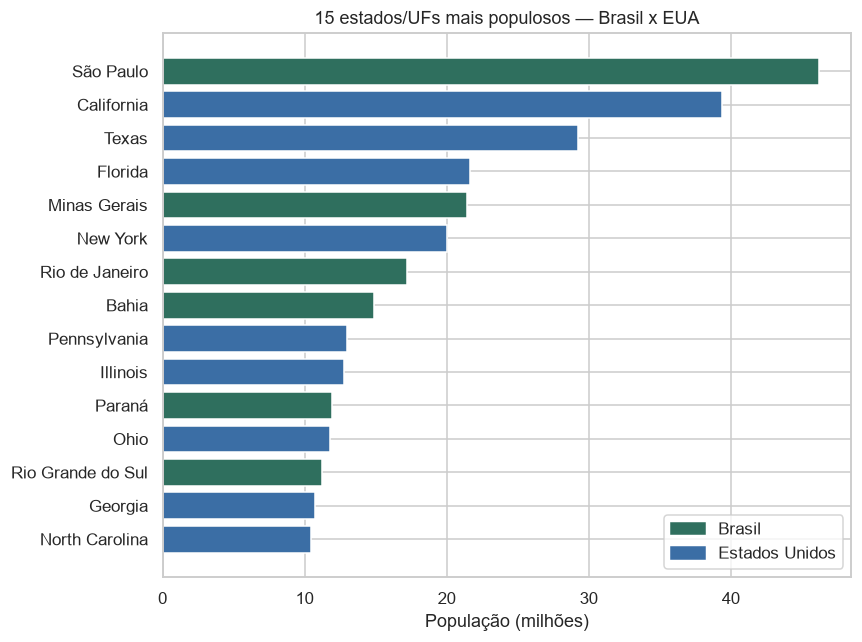

In [4]:
top15_pop = df.nlargest(15, "populacao").sort_values("populacao")

fig, ax = plt.subplots(figsize=(8, 6))
cores = top15_pop["pais"].map({"Brasil": "#2f6f5e", "Estados Unidos": "#3b6ea5"})
ax.barh(top15_pop["unidade_nome"], top15_pop["populacao"] / 1e6, color=cores)
ax.set_xlabel("População (milhões)")
ax.set_title("15 estados/UFs mais populosos — Brasil x EUA")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#2f6f5e", "#3b6ea5"]]
ax.legend(handles, ["Brasil", "Estados Unidos"], loc="lower right")
plt.tight_layout()
plt.show()


## 3. Densidade demográfica: os distritos federais são outliers em ambos os países

Densidade tem uma cauda longa nos dois países — por isso o eixo em escala
logarítmica. Um padrão salta aos olhos: **o Distrito Federal (Brasil) e o
District of Columbia (EUA) são, disparado, as unidades mais densas dos seus
respectivos países** — ambos são a capital federal, sem "zona rural" para
puxar a densidade pra baixo.


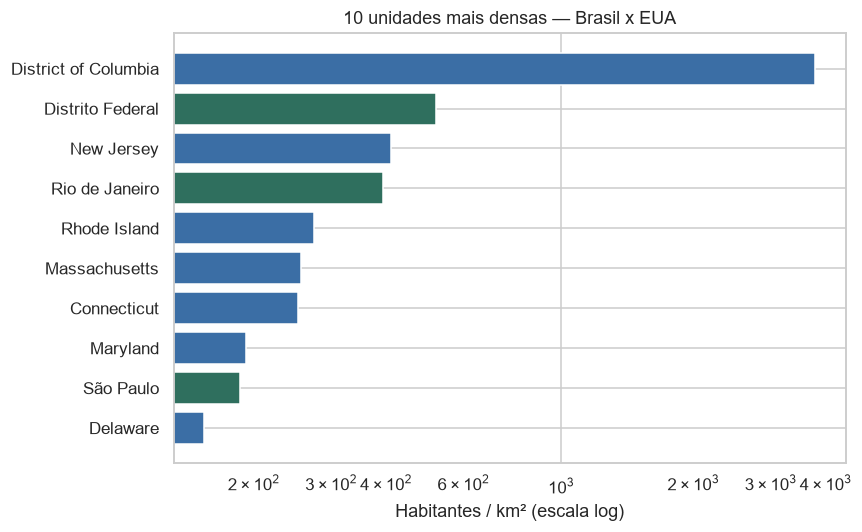

In [5]:
top10_densidade = df.nlargest(10, "densidade_hab_km2").sort_values("densidade_hab_km2")

fig, ax = plt.subplots(figsize=(8, 5))
cores = top10_densidade["pais"].map({"Brasil": "#2f6f5e", "Estados Unidos": "#3b6ea5"})
ax.barh(top10_densidade["unidade_nome"], top10_densidade["densidade_hab_km2"], color=cores)
ax.set_xscale("log")
ax.set_xlabel("Habitantes / km² (escala log)")
ax.set_title("10 unidades mais densas — Brasil x EUA")
plt.tight_layout()
plt.show()


In [6]:
df_capitais = df[df.unidade_sigla.isin(["DF", "DC"])][["pais", "unidade_nome", "densidade_hab_km2"]]
df_capitais


,pais,unidade_nome,densidade_hab_km2
6,Brasil,Distrito Federal,520.058744
35,Estados Unidos,District of Columbia,3788.074605


## 4. Escolaridade superior: uma diferença consistente, não só de topo

Comparando a % de pessoas com 25+ anos que completaram o superior
(Brasil: superior completo · EUA: bacharelado ou mais).


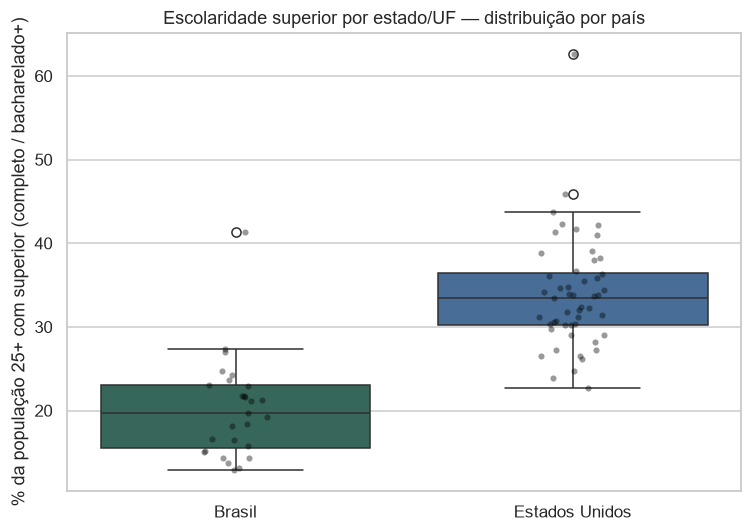

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x="pais", y="pct_educacao_superior", hue="pais",
            palette={"Brasil": "#2f6f5e", "Estados Unidos": "#3b6ea5"}, legend=False, ax=ax)
sns.stripplot(data=df, x="pais", y="pct_educacao_superior", color="black", alpha=0.4, size=4, ax=ax)
ax.set_ylabel("% da população 25+ com superior (completo / bacharelado+)")
ax.set_xlabel("")
ax.set_title("Escolaridade superior por estado/UF — distribuição por país")
plt.tight_layout()
plt.show()


In [8]:
medias_educ = df.groupby("pais")["pct_educacao_superior"].agg(["mean", "median", "min", "max"])
medias_educ


,mean,median,min,max
pais,,,,
Brasil,20.166667,19.700000,12.900000,41.300000
Estados Unidos,33.875648,33.463338,22.711161,62.636093


## 5. Renda relativa x escolaridade: o mesmo padrão nos dois países?

Usando `renda_indice_relativo` (100 = média do próprio país) para poder
plotar os dois países no mesmo eixo sem misturar `R$` com `US$`.


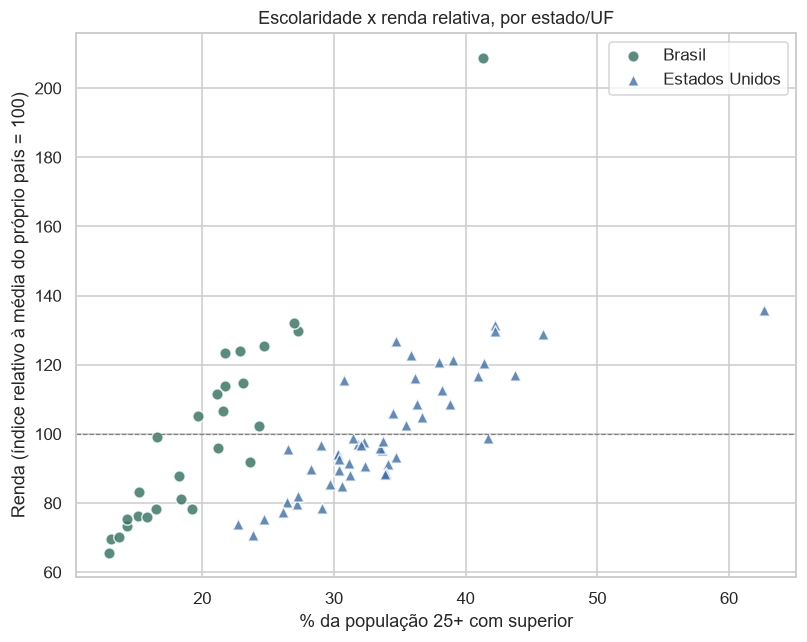

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 6))
for pais, cor, marcador in [("Brasil", "#2f6f5e", "o"), ("Estados Unidos", "#3b6ea5", "^")]:
    sub = df[df.pais == pais]
    ax.scatter(sub["pct_educacao_superior"], sub["renda_indice_relativo"],
               label=pais, color=cor, marker=marcador, s=55, alpha=0.8, edgecolor="white")

ax.axhline(100, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("% da população 25+ com superior")
ax.set_ylabel("Renda (índice relativo à média do próprio país = 100)")
ax.set_title("Escolaridade x renda relativa, por estado/UF")
ax.legend()
plt.tight_layout()
plt.show()


In [10]:
correlacoes = df.groupby("pais").apply(
    lambda g: g["pct_educacao_superior"].corr(g["renda_indice_relativo"]),
    include_groups=False,
)
correlacoes.rename("correlacao_educacao_renda")


pais
Brasil            0.948089
Estados Unidos    0.825617
Name: correlacao_educacao_renda, dtype: float64

## 6. Dentro do Brasil: desigualdade regional

Só o Brasil tem a coluna `regiao` (o Census não devolve essa granularidade
na mesma chamada). Vale olhar como renda e educação variam entre as
grandes regiões brasileiras.


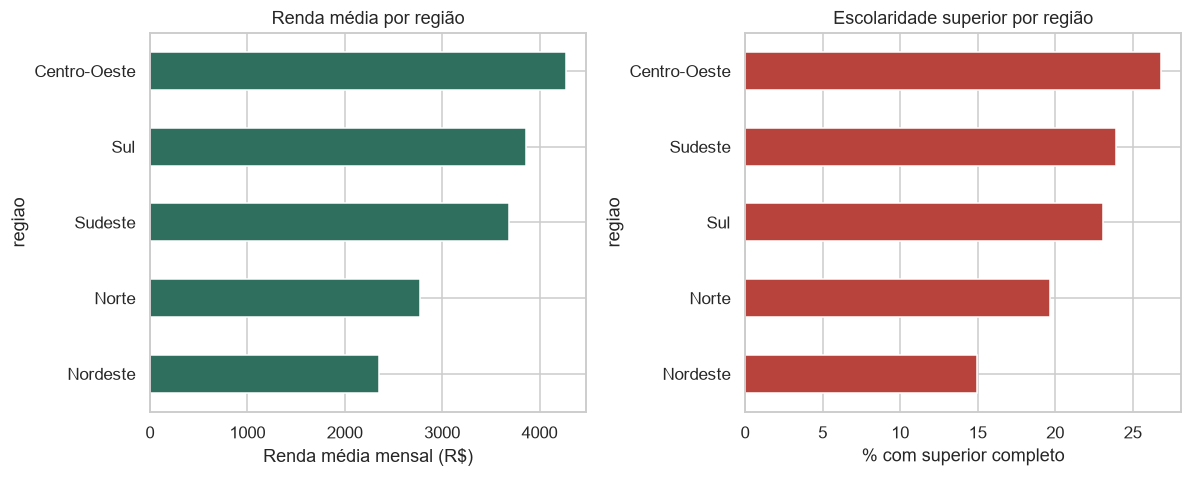

In [11]:
regiao_brasil = (
    df[df.pais == "Brasil"]
    .groupby("regiao")[["renda_valor", "pct_educacao_superior"]]
    .mean()
    .sort_values("renda_valor")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
regiao_brasil["renda_valor"].plot.barh(ax=axes[0], color="#2f6f5e")
axes[0].set_xlabel("Renda média mensal (R$)")
axes[0].set_title("Renda média por região")

regiao_brasil["pct_educacao_superior"].sort_values().plot.barh(ax=axes[1], color="#b8433d")
axes[1].set_xlabel("% com superior completo")
axes[1].set_title("Escolaridade superior por região")

plt.tight_layout()
plt.show()


## 7. Desigualdade entre estados: quem varia mais, Brasil ou EUA?

Comparando a dispersão da renda relativa entre os estados de cada país —
quanto maior o desvio-padrão do índice, mais desigual é a distribuição de
renda entre as unidades daquele país.


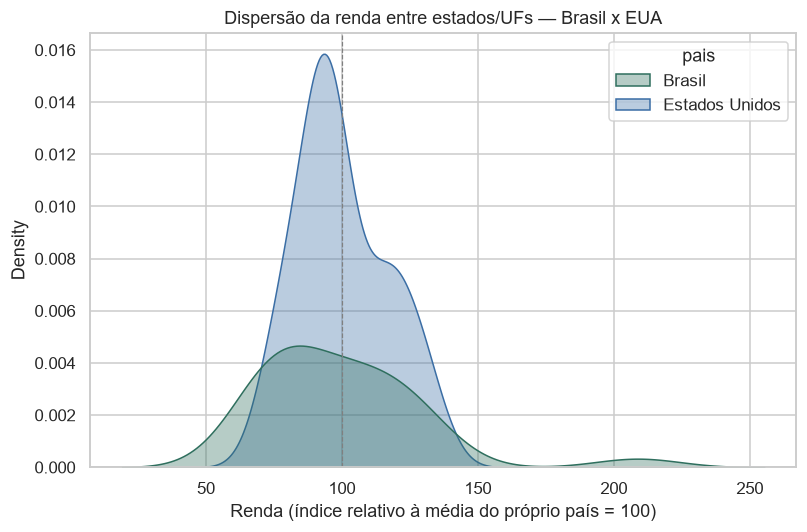

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.kdeplot(data=df, x="renda_indice_relativo", hue="pais", fill=True, alpha=0.35,
            palette={"Brasil": "#2f6f5e", "Estados Unidos": "#3b6ea5"}, ax=ax)
ax.axvline(100, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Renda (índice relativo à média do próprio país = 100)")
ax.set_title("Dispersão da renda entre estados/UFs — Brasil x EUA")
plt.tight_layout()
plt.show()


In [13]:
dispersao_renda = df.groupby("pais")["renda_indice_relativo"].std().rename("desvio_padrao_indice_renda")
dispersao_renda


pais
Brasil            29.995115
Estados Unidos    16.618921
Name: desvio_padrao_indice_renda, dtype: float64

## 8. Números de apoio para os achados

Antes de escrever as conclusões, alguns números exatos usados no texto
abaixo (desvio padrão da renda relativa, médias de escolaridade e a razão
de densidade entre a capital federal e o 2º estado/UF mais denso de cada
país).


In [14]:
capital_brasil = df[df.unidade_sigla == "DF"]["densidade_hab_km2"].iloc[0]
runner_up_brasil = df[(df.pais == "Brasil") & (df.unidade_sigla != "DF")]["densidade_hab_km2"].max()

capital_eua = df[df.unidade_sigla == "DC"]["densidade_hab_km2"].iloc[0]
runner_up_eua = df[(df.pais == "Estados Unidos") & (df.unidade_sigla != "DC")]["densidade_hab_km2"].max()

nome_runner_up_br = df.loc[(df.pais == "Brasil") & (df.densidade_hab_km2 == runner_up_brasil), "unidade_nome"].iloc[0]
nome_runner_up_us = df.loc[(df.pais == "Estados Unidos") & (df.densidade_hab_km2 == runner_up_eua), "unidade_nome"].iloc[0]

print(f"Brasil: DF = {capital_brasil:.1f} hab/km² | 2º lugar ({nome_runner_up_br}) = {runner_up_brasil:.1f} hab/km² | razão = {capital_brasil / runner_up_brasil:.2f}x")
print(f"EUA:    DC = {capital_eua:.1f} hab/km² | 2º lugar ({nome_runner_up_us}) = {runner_up_eua:.1f} hab/km² | razão = {capital_eua / runner_up_eua:.2f}x")
print()
print("Desvio-padrão do índice de renda relativa:")
print(dispersao_renda)
print()
print("Escolaridade superior — média por país:")
print(medias_educ["mean"])


Brasil: DF = 520.1 hab/km² | 2º lugar (Rio de Janeiro) = 393.5 hab/km² | razão = 1.32x
EUA:    DC = 3788.1 hab/km² | 2º lugar (New Jersey) = 409.6 hab/km² | razão = 9.25x

Desvio-padrão do índice de renda relativa:
pais
Brasil            29.995115
Estados Unidos    16.618921
Name: desvio_padrao_indice_renda, dtype: float64

Escolaridade superior — média por país:
pais
Brasil            20.166667
Estados Unidos    33.875648
Name: mean, dtype: float64


## 9. Três achados principais

**1. A renda entre estados varia bem mais no Brasil do que nos EUA.**
O desvio-padrão do índice de renda relativa é de aproximadamente **30
pontos no Brasil, contra ~17 nos EUA** (seção 8). Ou seja: mesmo
normalizando pela própria média nacional de cada país, os estados
brasileiros se afastam muito mais da média do que os estados americanos —
a desigualdade regional de renda é estruturalmente maior aqui, não é só
um efeito de moeda ou de tamanho de país.

**2. A escolaridade superior é consistentemente mais alta nos EUA — não é
só o topo que puxa a média.** A média de pessoas com 25+ anos que
completaram o superior é de **~34% nos EUA contra ~20% no Brasil** (seção
4 e 8), e mesmo a melhor UF brasileira (Distrito Federal, ~41%) fica
abaixo da média americana. A distribuição inteira está deslocada, não é
um caso de poucos estados de elite puxando a média pra cima.

**3. As duas capitais federais são disparadamente as unidades mais densas
dos seus países — mas em escalas muito diferentes.** DF e DC são, cada
um no seu país, a unidade mais densamente povoada (seção 3 e 8). No
Brasil, o DF tem densidade parecida com a do Rio de Janeiro (2º lugar,
**1,32x**) — uma diferença moderada; nos EUA, o DC chega a ter **9,25x**
a densidade do 2º colocado (New Jersey) — uma disparidade bem maior. O
"efeito capital administrativa" existe nos dois países, mas é
proporcionalmente muito mais extremo nos EUA (números exatos na seção 8).

### Limitações

- Renda e escolaridade usam metodologias e recortes etários/de unidade
  diferentes entre IBGE e Census (ver seção 1) — a comparação é robusta
  em termos relativos, não em valor absoluto.
- Densidade usa fontes de área de anos diferentes (Censo 2010 no Brasil,
  Gazetteer 2021 nos EUA) — a área muda pouco ano a ano, então o impacto é
  mínimo, mas vale registrar.
- Cada UF/estado é tratado com peso igual nos gráficos de distribuição
  (boxplot, KDE) mesmo tendo populações muito diferentes entre si — ou
  seja, isso mede desigualdade *entre estados*, não entre pessoas.
